In [20]:
import numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt

# Data

In [35]:
Y = pd.read_csv('SP500.csv')['SP500'].apply(lambda x: np.log(x)).diff().dropna().to_numpy()

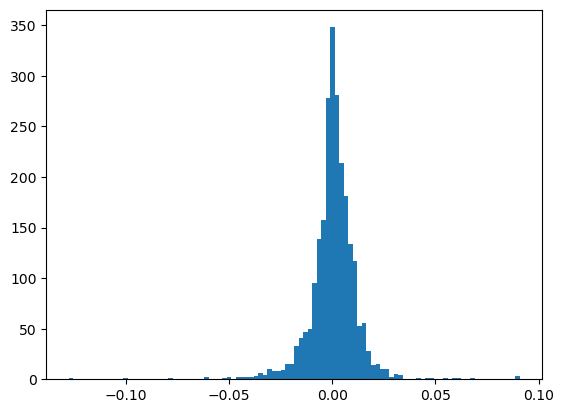

In [40]:
plt.hist(Y, bins=100);

# Priors

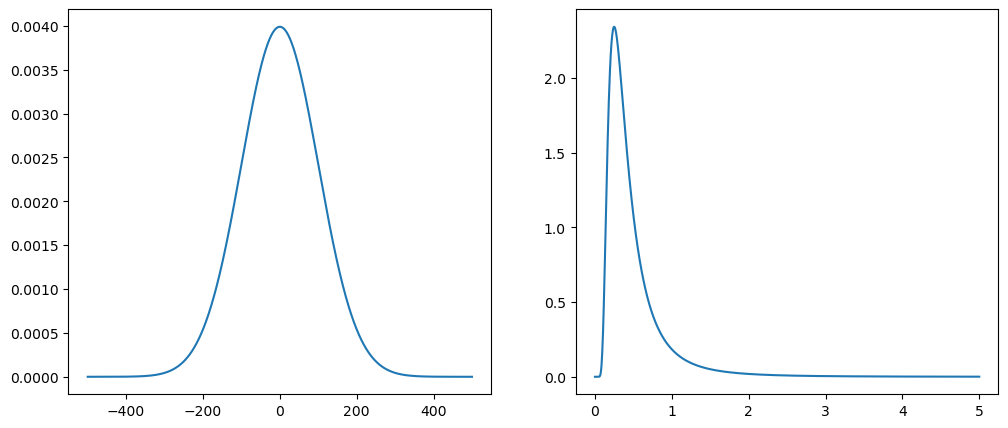

In [17]:
mu_prior_std = 100.0

mu_grid = np.linspace(-5*mu_prior_std, 5*mu_prior_std, 1000)

sigma_prior_alpha = 3

sigma_grid = np.linspace(0, 5, 1000)

f, ax = plt.subplots(1,2,figsize=(12,5))

ax[0].plot(mu_grid, st.norm.pdf(mu_grid, scale=mu_prior_std))
ax[1].plot(sigma_grid, st.invgamma.pdf(sigma_grid, a=sigma_prior_alpha))

# Likelihood and posterior

The shared likelihood-function between $(\mu, \sigma)$ is:
\begin{align*}
\ell(\mu, \sigma^2) &= \left( \frac{1}{\sqrt{2 \pi \sigma^2}} \right)^T \exp \left( -\frac{\sum_{t=1}^T (y_t-\mu)^2}{2\sigma^2}\right) \propto \left( \frac{1}{\sigma} \right)^T \exp \left( -\frac{\sum_{t=1}^T (y_t-\mu)^2}{2\sigma^2}\right)
\end{align*}
, whereby the posterior for $\mu$ given $\sigma^2$ becomes:
$$\Rightarrow p(\mu \vert \sigma^2, y) \propto \left( \frac{1}{\sigma} \right)^T  \exp \left( -\frac{\sum_{t=1}^T (y_t-\mu)^2}{2\sigma^2}\right) \left( \frac{1}{\sigma_\mu} \right)^T  \exp \left(-\frac{(\mu-\mu_\mu)^2}{2\sigma_\mu^2} \right)=\left( \frac{1}{\sigma \sigma_\mu} \right)^T \exp \left( -\frac{\sum_{t=1}^T (y_t-\mu)^2}{2\sigma^2}-\frac{(\mu-\mu_\mu)^2}{2\sigma_\mu^2}\right)$$
, which can be shown to be $\mu \vert \sigma^2, y \sim \mathcal{N} \left( \mu_N, \sigma^2_N \right)$ with $\sigma^2_N = \left( \frac{T}{\sigma^2} + \frac{1}{\sigma^2_\mu} \right)^{-1}$ and $\mu_N = \sigma^2_N \left( \frac{\sum_{t=1}^T y_t}{\sigma^2} + \frac{\mu_\mu}{\sigma^2_\mu} \right)$.

Similarly the posterior for $\sigma^2$ given $\mu$ becomes: $\sigma^2 \vert y, \mu \sim \mathcal{IG}(\alpha_N, \beta_N)$ with $\alpha_N=\alpha_{\sigma^2}+\frac{T}{2}$ and $\beta_N=\beta_{\sigma^2} + \frac{1}{2} \sum_{t=1}^T {(y_t-\mu)^2}$

In [ ]:
def sigma_sq_N(T, sigma_k, sigma_prior):

    return (T/(sigma_k**2) + 1/(sigma_prior**2))**(-1)

def mu_N(Y, T, sigma_k, mu_prior, sigma_prior):

    sigma_sq_N_ = sigma_sq_N(T,sigma_k, mu_prior, sigma_prior)

    return sigma_sq_N_*(np.sum(Y)/(sigma_k**2) + mu_prior/(sigma_prior**2))

def alpha_N(T, alpha_prior):

    return alpha_prior + T/2

def beta_N(Y, mu_k, beta_prior):

    return beta_prior + 0.5*(np.sum(Y-mu_k))

# Gibbs Sampler

In [ ]:
sigma_sq_init = np.var(Y)

def Gibbs_step(sigma_sq_lag):

    mu_mu = mu_N()

In [42]:
sigma_sq_init

np.float64(0.00013087596389239878)